Logistic Regression 은 회귀가 들어가지만 분류알고리즘 이다.
주어진 독립변수를 가지고 1/0(참/거짓) 을 분류하는데 사용 된다.

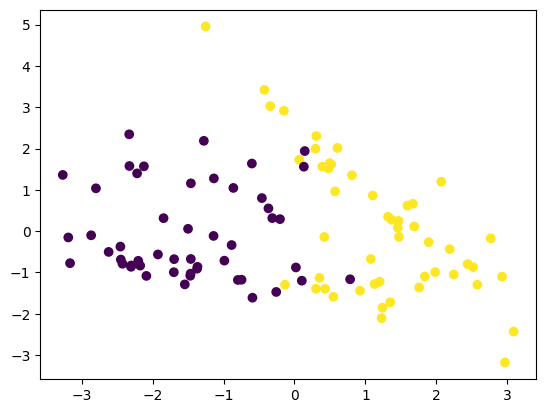

In [6]:
from sklearn.datasets import make_classification
from matplotlib import pyplot as plt

# 무조건 같은 형태를 만들기 위해서 random_state 지정
x,y = make_classification(n_features=2, n_classes=2, n_informative=2, n_clusters_per_class=2, n_redundant=0, random_state=33)
#print(x)
#print(y)
plt.scatter(x[:,0], x[:,1], c=y)
plt.show()

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.3, stratify=y, random_state=23)
# C : 규제강도(0.01~100) 0.01 은 규제가 강함, 100은 규제가 약함
# 규제가 강할수록 과소적합 우려가 있고 약할수록 과대적합 우려가 있다.
# 과대적합의 경우 심한 곡선모양을 생각 하자
model = LogisticRegression(C=100).fit(x_train, y_train)
print(model.score(x_test, y_test))

1.0


In [8]:
print(f'계수(coef) {model.coef_}') # 입력변수 관련
print(f'절편(intercept) {model.intercept_}') # 편향,기울기 관련

계수(coef) [[3.10501926 0.62967968]]
절편(intercept) [0.12155739]


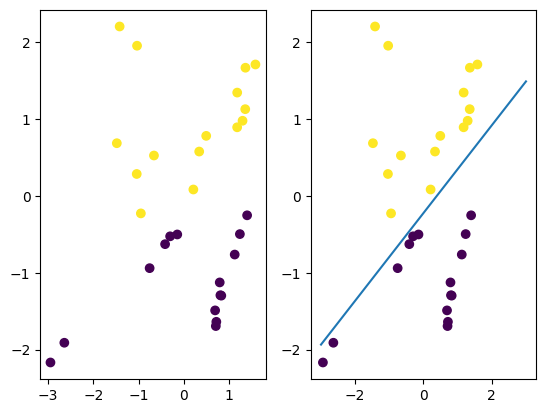

In [ ]:
import numpy as np

pred = model.predict(x_test)
plt.subplot(121)
plt.scatter(x_test[:,0], x_test[:,1], c=y_test)
plt.subplot(122)
plt.scatter(x_test[:,0], x_test[:,1], c=pred)

#분류라인 그리기
line = np.linspace(-3,3)
for coef,inter in zip(model.coef_, model.intercept_):
  plt.plot(line, -(line*coef[0] + inter)/coef[1]) # 뭔지 모르지만 일단 해 보자

plt.ylim(-5,5)
plt.show()

In [ ]:
# 유방암 데이터(30개 특성이 있는) 로 암인지 아닌지를 구분
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()
print(list(cancer.keys()))
x = cancer.data
y = cancer.target
print(x.shape)

['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module']
(569, 30)


In [ ]:
x_train,x_test,y_train,y_test = train_test_split(x,y, stratify=y, random_state=42)

c_list = [0.001,0.01,0.1,1,10,100]
test_score = []
train_score = []

for c in c_list:
  # penalty = [l1,l2,elastic,none]
  # 입력변수 특징에 따라서 l1, 또는 elastic 은 사용할수 없다.
  model = LogisticRegression(C=c,penalty='l2', max_iter=100000).fit(x_train, y_train)
  train_score.append(model.score(x_train,y_train))
  test_score.append(model.score(x_test,y_test))

[0 1 2 3 4 5]


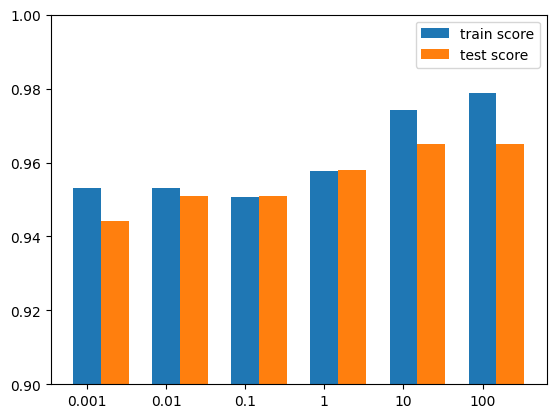

In [ ]:
#print(test_score)
#print(train_score)
bar_width=0.35
index = np.arange(0,len(c_list))
print(index)
plt.bar(index, train_score, width=bar_width,label='train score')
plt.bar(index+bar_width, test_score,width=bar_width, label='test score')
plt.ylim(0.9,1)
plt.xticks(index, c_list)
plt.legend()
plt.show()